**Name:** Spoorthi A N
**SRN:** PES2UG24CS515
**Section:** I
**Course:** UE24CS342AA9 - Visualization of Data, Understanding and Interpretation
**Activity:** Unit 4 PPT 4 - Should We Trust the Alarm? (FreshKart Cold-Chain Case)

---


# Activity: Should We Trust the Alarm? — FreshKart Cold-Chain Case

**Unit 4 · AI-Assisted Visualization · AI-Assisted Pattern and Anomaly Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

FreshKart's dark stores keep frozen food in **8 freezers** (one per store in Bengaluru, Pune and Hyderabad). Each freezer reports its temperature every hour. Last month FreshKart bought **ColdSense**, an AI service that scores every reading for "anomaly" and raises an alert when the score is **≥ 0.5**.

Cold-chain lead **Ravi** has six weeks of readings, the ColdSense scores, and the **maintenance log** (what technicians actually found). His technicians are tired of being sent out at night. He asks:

> *"Is ColdSense's alert feed trustworthy? Which alerts should my team chase, and what is it missing?"*

**You are the analyst.** Use the data and the visualizations to verify, correct or reject what the vendor claims.

**Ground rules (from the lecture):** an AI score is a *derived attribute*: look at it, don't only threshold it · flags are **candidates, not conclusions** · report precision and recall, not accuracy · scale emphasis to confidence.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_coldchain.csv` (synthetic)

| Column | Meaning |
|---|---|
| `timestamp` | hour of the reading (1 Aug – 11 Sep 2026) |
| `city`, `store_id`, `freezer_id` | where the freezer is |
| `temp_c` | freezer temperature (°C); normal is about −18 °C |
| `door_opens` | number of door openings in that hour (busy by day, quiet at night) |
| `compressor_kw` | compressor power draw (kW) |
| `ai_score`, `ai_flag` | ColdSense anomaly score (0–1) and alert (1 if score ≥ 0.5) |
| `confirmed_fault`, `fault_type` | from the maintenance log: 1 if technicians confirmed a real fault in that hour, and what it was |

**Domain note from the maintenance team:** every freezer runs an automatic **defrost cycle from 02:00 to 04:00** each night. The heater warms the coil, so the temperature rises for those two hours. That is normal.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})
GREY, ACCENT, BLUE = "#bdbdbd", "#d95f02", "#4c78a8"

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_coldchain.csv", parse_dates=["timestamp"])
df["hour"] = df["timestamp"].dt.hour
df.head()

,timestamp,city,store_id,freezer_id,temp_c,door_opens,compressor_kw,ai_score,ai_flag,confirmed_fault,fault_type,hour
0,2026-08-01,Bengaluru,B1,FZ-B1,-18.1,0,1.29,0.000,0,0,NaN,0
1,2026-08-01,Bengaluru,B2,FZ-B2,-18.7,0,1.16,0.000,0,0,NaN,0
2,2026-08-01,Bengaluru,B3,FZ-B3,-17.7,0,1.21,0.000,0,0,NaN,0
3,2026-08-01,Hyderabad,H1,FZ-H1,-17.8,0,1.30,0.037,0,0,NaN,0
4,2026-08-01,Hyderabad,H2,FZ-H2,-18.2,0,1.32,0.035,0,0,NaN,0


## ColdSense's monthly report (to be validated)

| # | Vendor statement |
|---|---|
| 1 | "ColdSense is **97.9% accurate**, so its alerts can be trusted." |
| 2 | "**Most faults happen around 2 am.** We recommend a night technician." |
| 3 | "**All 10 compressor trips** in the period were caught." |
| 4 | "Freezer **FZ-H2 ran without a single fault** in August." |
| 5 | "A reading of **−14 °C is abnormal** for any freezer, at any time." |
| 6 | "An alert with a score of **0.92 means a 92% chance** of a real fault." |
| 7 | "The **default threshold of 0.5** is the best setting for FreshKart." |
| 8 | "A new FZ-B1 reading of **−15.9 °C at 14:00** is **15 standard errors** above normal: a definite fault." |

---
## Part 1 · Data abstraction: items, attributes and derived attributes

Munzner: before choosing a view, ask what the **items** and **attributes** are. The AI does not change the items; it **derives** new attributes.

In [2]:
derived_cols = ["ai_score", "ai_flag"]        # TODO: list the column(s) that ColdSense derived (not measured by the freezer or written by technicians)
n_alerts = (df["ai_flag"] == 1).sum()            # TODO: number of rows with an alert (ai_flag == 1)
fault_rate_pct = round(df["confirmed_fault"].mean() * 100, 2)            # TODO: % of rows that are confirmed faults, 2 decimals (this is the base rate)

if ready(derived_cols, n_alerts, fault_rate_pct):
    print(f"derived: {derived_cols} | alerts: {n_alerts} | faults: {df.confirmed_fault.sum()} of {len(df)} rows ({fault_rate_pct}%)")
    display(df[df.confirmed_fault == 1].groupby("fault_type").size().rename("fault hours"))


derived: ['ai_score', 'ai_flag'] | alerts: 159 | faults: 46 of 8064 rows (0.57%)


fault_type
compressor trip         10
defrost heater stuck    11
sensor frozen           25
Name: fault hours, dtype: int64

**✏️ Your answer (Part 1):** `ai_score` is quantitative and `ai_flag` is binary. Which **visual channel** suits each, and what information does the flag throw away that the score keeps?

*My answer:* `ai_score` is a continuous value between 0 and 1, so it needs a channel that can show small differences, like position on a line or scatter plot, or a continuous colour scale. `ai_flag` is just yes/no, so a simple category channel is enough, like two colours or two marker shapes. When the score is collapsed into the flag, we lose *how confident* the model was. A reading with 0.51 and one with 0.98 both become the same red dot, so a technician cannot tell a borderline case from an almost certain fault.


---
## Part 2 · Distributions: bin width and the score distribution

### 2a · Temperature histogram

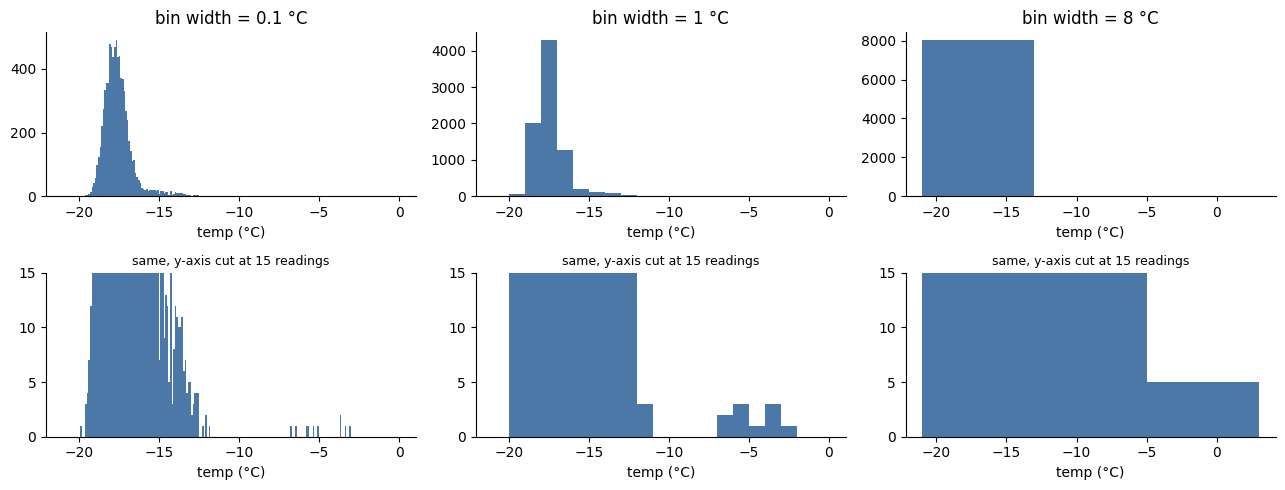

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5))
for col, w in enumerate([0.1, 1, 8]):
    for row, top in enumerate([None, 15]):
        ax = axes[row, col]
        ax.hist(df["temp_c"], bins=np.arange(-21, 0 + w, w), color=BLUE)
        if top:
            ax.set_ylim(0, top)
            ax.set_title(f"same, y-axis cut at {top} readings", fontsize=9)
        else:
            ax.set_title(f"bin width = {w} °C")
        ax.set_xlabel("temp (°C)")
plt.tight_layout()
plt.show()

warm_tail_visible_bins = [0.1, 1]   # TODO: in the bottom row, which bin width(s) show the very warm readings (above -8 °C) as a separate group? a list, e.g. [0.1]
n_warm_readings = int((df["temp_c"] > -8).sum())          # TODO: how many readings are warmer than -8 °C? (count them with code)


### 2b · Look at the AI scores before trusting the cut-off
Wilke: compare groups with overlapping densities, not stacked histograms.

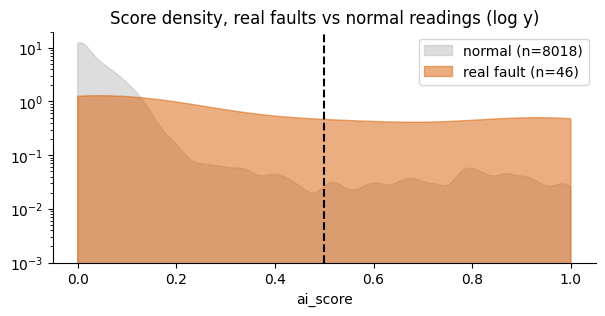

In [4]:
xs = np.linspace(0, 1, 300)
fig, ax = plt.subplots(figsize=(7, 3))
for lab, col in [(0, GREY), (1, ACCENT)]:
    s = df.loc[df.confirmed_fault == lab, "ai_score"]
    ax.fill_between(xs, stats.gaussian_kde(s)(xs), color=col, alpha=.5, label=f"{'real fault' if lab else 'normal'} (n={len(s)})")
ax.axvline(0.5, color="k", ls="--")
ax.set_yscale("log")
ax.set_ylim(1e-3, 20)
ax.set_xlabel("ai_score")
ax.legend()
ax.set_title("Score density, real faults vs normal readings (log y)")
plt.show()

scores_separate_faults = False   # TODO: True/False - is there a clean score cut-off that separates real faults from normal readings?


**✏️ Your answer (Part 2):** Why is a histogram "a parameterised algorithm", and what would you tell a colleague who says *"the 8 °C histogram shows no anomalies"*?

*My answer:* A histogram is called a parameterised algorithm because its output depends on a parameter we choose, the bin width, not only on the data. The same 8,064 readings can look like one smooth block or like separate peaks just because the bin width changed. I would tell the colleague that the 8 °C bins are too wide to show anything. Only 10 out of 8,064 readings are warmer than -8 °C, so with 8 °C bins those few warm readings get merged into the same bin as thousands of normal ones and disappear. With 0.1 or 1 °C bins the same readings show up clearly as a small separate cluster near 0 °C.


---
## Part 3 · Outlier rules on a short window (vendor statement 3)

Ten consecutive readings from **FZ-P1**, 12 Aug 06:00–15:00. One of them is a compressor trip.

In [5]:
window = df[(df.freezer_id == "FZ-P1") & (df.timestamp >= "2026-08-12 06:00") & (df.timestamp < "2026-08-12 16:00")]
v = window["temp_c"].values
print(window[["timestamp", "temp_c", "fault_type"]].to_string(index=False))

z_max = np.max(np.abs((v - v.mean()) / np.std(v, ddof=1)))          # TODO: the largest |z| in v, using the sample SD (hint: np.std(v, ddof=1))
q1, q3 = np.percentile(v, [25, 75])
upper_fence = q3 + 1.5 * (q3 - q1)    # TODO: Q3 + 1.5 * IQR

if ready(z_max, upper_fence):
    print(f"largest |z| = {z_max:.2f} -> flagged by |z| > 3? {z_max > 3}")
    print(f"upper IQR fence = {upper_fence:.2f} °C -> trip flagged by IQR rule? {v.max() > upper_fence}")
    print(f"largest |z| possible with n = {len(v)}: {(len(v) - 1) / np.sqrt(len(v)):.2f}")


          timestamp  temp_c      fault_type
2026-08-12 06:00:00   -17.5             NaN
2026-08-12 07:00:00   -18.2             NaN
2026-08-12 08:00:00   -17.4             NaN
2026-08-12 09:00:00   -17.7             NaN
2026-08-12 10:00:00   -16.6             NaN
2026-08-12 11:00:00    -3.6 compressor trip
2026-08-12 12:00:00   -17.0             NaN
2026-08-12 13:00:00   -16.8             NaN
2026-08-12 14:00:00   -17.7             NaN
2026-08-12 15:00:00   -17.7             NaN
largest |z| = 2.83 -> flagged by |z| > 3? False
upper IQR fence = -15.58 °C -> trip flagged by IQR rule? True
largest |z| possible with n = 10: 2.85


**✏️ Your answer (Part 3):** Explain in two sentences why the z-score rule missed the trip here (use the word *masking*) and why the IQR rule did not.

*My answer:* The z-score rule uses the mean and standard deviation of the same small sample, and the one huge outlier (-3.6 °C when everything else is around -17 °C) blows up the standard deviation, so the outlier *masks* itself and its |z| stays under 3 (with 10 points, the largest possible |z| is only about 2.85). The IQR rule is built from the middle 50% of the values (Q1 to Q3), so one extreme value barely moves it. The fence stays tight around the normal readings, and the trip at -3.6 °C lands far above it and gets flagged.


---
## Part 4 · How good is ColdSense? (vendor statement 1)

In [6]:
flag = df.ai_flag == 1
real = df.confirmed_fault == 1

TP = int((flag & real).sum())    # TODO: alerts that were real faults
FP = int((flag & ~real).sum())    # TODO: alerts on normal readings (false alarms)
FN = int((~flag & real).sum())    # TODO: real faults with no alert (missed)
TN = int((~flag & ~real).sum())    # TODO: normal readings with no alert

if ready(TP, FP, FN, TN):
    display(pd.DataFrame([[TP, FN], [FP, TN]], index=["real fault", "normal"], columns=["alert", "no alert"]))


,alert,no alert
real fault,16,30
normal,143,7875


In [7]:
precision = TP / (TP + FP)              # TODO
recall = TP / (TP + FN)                 # TODO
f1 = 2 * precision * recall / (precision + recall)                     # TODO
accuracy = (TP + TN) / len(df)                # TODO
flag_nothing_accuracy = (~real).mean()  # TODO: accuracy of a "detector" that never raises an alert

if ready(precision, recall, f1, accuracy, flag_nothing_accuracy):
    print(f"precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f} | accuracy = {accuracy:.1%} | never-alert accuracy = {flag_nothing_accuracy:.1%}")


precision = 0.10 | recall = 0.35 | F1 = 0.16 | accuracy = 97.9% | never-alert accuracy = 99.4%


**✏️ Your answer (Part 4):** Rewrite vendor statement 1 so it is honest. Use precision and recall, and say in plain words what they mean for Ravi's technicians (how many call-outs are wasted, how many faults are missed).

*My answer:* Honest version: "ColdSense's 97.9% accuracy sounds good but it is misleading, because faults are very rare (only 0.57% of readings). A system that never raised any alert at all would still be 99.4% accurate. What actually matters is that ColdSense has precision of about 0.10 and recall of about 0.35." For Ravi's technicians this means that out of every 10 alerts they go and check, about 9 are false alarms, so most night call-outs are wasted. And out of all the real faults, only about 1 in 3 raises an alert, so roughly 2 out of 3 real faults are missed completely.


---
## Part 5 · Thresholds and costs (vendor statement 7)

A missed fault can spoil a freezer of stock (cost ≈ **40** units); a false call-out costs **1** unit of technician time.

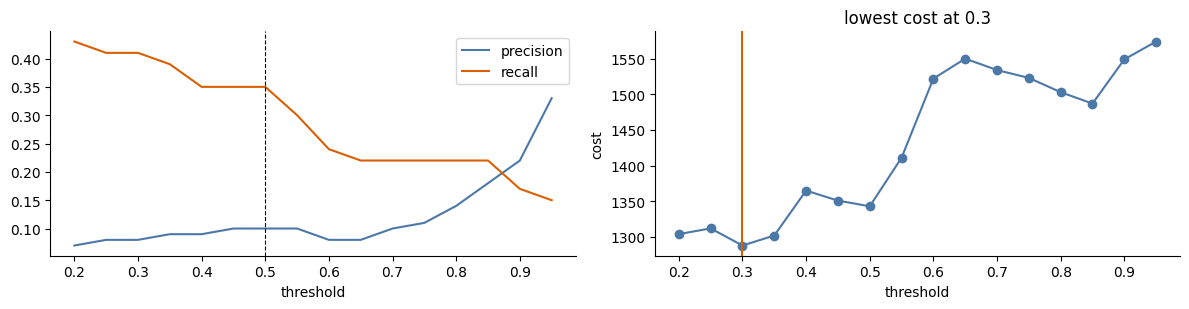

,threshold,TP,FP,FN,precision,recall,cost
0,0.20,20,264,26,0.07,0.43,1304
1,0.25,19,232,27,0.08,0.41,1312
2,0.30,19,208,27,0.08,0.41,1288
3,0.35,18,182,28,0.09,0.39,1302
4,0.40,16,165,30,0.09,0.35,1365
5,0.45,16,151,30,0.10,0.35,1351
6,0.50,16,143,30,0.10,0.35,1343
7,0.55,14,131,32,0.10,0.30,1411
8,0.60,11,122,35,0.08,0.24,1522
9,0.65,10,110,36,0.08,0.22,1550


In [8]:
grid = np.round(np.arange(0.20, 0.96, 0.05), 2)
sweep = pd.DataFrame({"threshold": grid})
sweep["TP"] = [((df.ai_score >= g) & real).sum() for g in grid]
sweep["FP"] = [((df.ai_score >= g) & ~real).sum() for g in grid]
sweep["FN"] = real.sum() - sweep["TP"]
sweep["precision"] = (sweep.TP / (sweep.TP + sweep.FP)).round(2)
sweep["recall"] = (sweep.TP / real.sum()).round(2)

sweep["cost"] = 40 * sweep["FN"] + 1 * sweep["FP"]          # TODO: 40 * FN + 1 * FP
best_threshold = sweep.loc[sweep["cost"].astype(float).idxmin(), "threshold"]         # TODO: the threshold with the lowest cost (hint: sweep.loc[sweep["cost"].astype(float).idxmin(), "threshold"])

if ready(best_threshold) and sweep["cost"].notna().all():
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
    ax[0].plot(sweep.threshold, sweep.precision, color=BLUE, label="precision")
    ax[0].plot(sweep.threshold, sweep.recall, color=ACCENT, label="recall")
    ax[0].axvline(0.5, color="k", ls="--", lw=.8)
    ax[0].legend()
    ax[0].set_xlabel("threshold")
    ax[1].plot(sweep.threshold, sweep.cost.astype(float), color=BLUE, marker="o")
    ax[1].axvline(best_threshold, color=ACCENT)
    ax[1].set_xlabel("threshold")
    ax[1].set_ylabel("cost")
    ax[1].set_title(f"lowest cost at {best_threshold}")
    plt.tight_layout()
    plt.show()
    display(sweep)


**✏️ Your answer (Part 5):** Even at the best threshold, recall stays low. Why can no threshold fix this detector? (Hint: look at *which* faults are never scored high.)

*My answer:* Changing the threshold only moves the cut-off on the scores the model has already given. It cannot help when a fault never gets a high score in the first place. That is exactly what happens with the frozen-sensor faults: the model scores each reading on its own, and a stuck sensor gives the same flat reading every hour, which looks perfectly normal hour by hour, so its score stays near 0. No threshold, even a very low one, can catch a fault that the scoring itself never marks as unusual. The problem is in what the model looks at, not in where we put the cut-off.


---
## Part 6 · Where do the errors come from?

### 6a · When do the false alarms happen? (vendor statement 2)

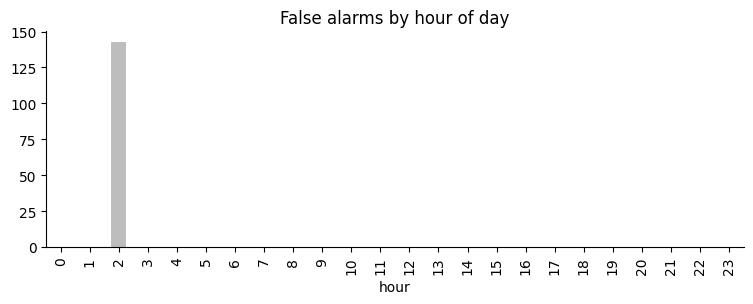

100% of false alarms happen at 2:00


In [9]:
fp_rows = df[flag & ~real]
fp_rows.groupby("hour").size().reindex(range(24), fill_value=0).plot.bar(color=GREY, title="False alarms by hour of day", figsize=(9, 2.8))
plt.show()

fp_peak_hour = int(fp_rows.groupby("hour").size().reindex(range(24), fill_value=0).idxmax())          # TODO: the hour with the most false alarms (an int)
fp_share_at_peak = fp_rows.groupby("hour").size().reindex(range(24), fill_value=0).max() / len(fp_rows)         # TODO: share of all false alarms that fall in that hour (0-1)

if ready(fp_peak_hour, fp_share_at_peak):
    print(f"{fp_share_at_peak:.0%} of false alarms happen at {fp_peak_hour}:00")


### 6b · Which faults does ColdSense miss?

In [10]:
caught = df[real].groupby("fault_type")["ai_flag"].agg(caught="sum", fault_hours="size")
caught["recall"] = (caught.caught / caught.fault_hours).round(2)
display(caught)

never_caught_type = "sensor frozen"     # TODO: the fault type ColdSense never catches
anomaly_kind = "collective"    # TODO: is that a 'point', 'contextual' or 'collective' anomaly?


,caught,fault_hours,recall
fault_type,,,
compressor trip,10,10,1.00
defrost heater stuck,6,11,0.55
sensor frozen,0,25,0.00


### 6c · Contextual anomalies: compare each reading with its own hour

A **context-aware** baseline compares each reading with the same freezer at the same hour of day (median and MAD over the six weeks).

In [11]:
grp = df.groupby(["freezer_id", "hour"])["temp_c"]
df["hour_median"] = grp.transform("median")
df["hour_mad"] = grp.transform(lambda s: 1.4826 * stats.median_abs_deviation(s))

df["z_context"] = (df["temp_c"] - df["hour_median"]) / df["hour_mad"]       # TODO: (temp_c - hour_median) / hour_mad

if ready(*df["z_context"].head(1)):
    ctx_flag = df["z_context"].astype(float) > 4
    found = df[real & ctx_flag & ~flag]
    print(f"Real faults the context baseline catches but ColdSense missed: {len(found)}")
    display(found[["timestamp", "freezer_id", "temp_c", "hour_median", "z_context", "ai_score", "fault_type"]])
    print(f"False alarms at 02:00 under the context baseline: {(ctx_flag & ~real & (df.hour == 2)).sum()} (ColdSense: {(flag & ~real & (df.hour == 2)).sum()})")


Real faults the context baseline catches but ColdSense missed: 3


,timestamp,freezer_id,temp_c,hour_median,z_context,ai_score,fault_type
1279,2026-08-07 15:00:00,FZ-P2,-14.6,-17.50,4.890058,0.369,defrost heater stuck
4731,2026-08-25 15:00:00,FZ-H1,-14.8,-17.50,6.070417,0.388,defrost heater stuck
6273,2026-09-02 16:00:00,FZ-B2,-15.2,-17.35,4.143300,0.189,defrost heater stuck


False alarms at 02:00 under the context baseline: 0 (ColdSense: 143)


### 6d · Collective anomalies: a run of readings that is abnormal together

                           min                 max  count
freezer_id                                               
FZ-H2      2026-08-20 14:00:00 2026-08-20 22:00:00      9
FZ-P1      2026-09-06 12:00:00 2026-09-06 17:00:00      6


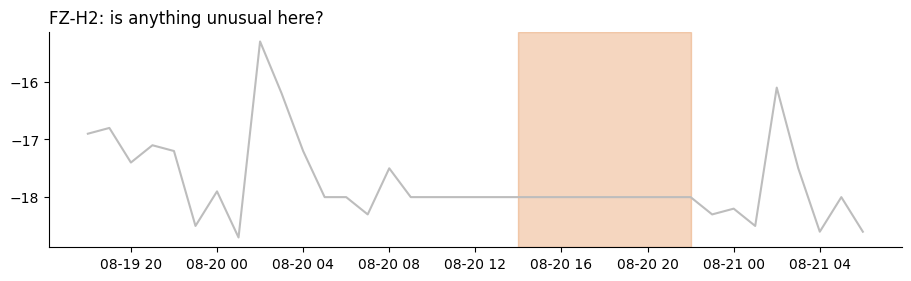

In [12]:
df = df.sort_values(["freezer_id", "timestamp"])
df["roll_sd_6h"] = df.groupby("freezer_id")["temp_c"].transform(lambda s: s.rolling(6).std())

flat = df[df["roll_sd_6h"] < 0.01]   # TODO: rows where the 6-hour rolling SD is (almost) zero, e.g. df[df["roll_sd_6h"] < 0.01]

if ready(flat):
    print(flat.groupby("freezer_id")["timestamp"].agg(["min", "max", "count"]))
    h2 = df[(df.freezer_id == "FZ-H2") & (df.timestamp.between("2026-08-19 18:00", "2026-08-21 06:00"))]
    fig, ax = plt.subplots(figsize=(11, 2.8))
    ax.plot(h2.timestamp, h2.temp_c, color=GREY)
    # TODO (drawing): highlight the WHOLE flat span on this chart, not single points (hint: ax.axvspan(start, end, color=ACCENT, alpha=.25))
    span = flat[flat.freezer_id == "FZ-H2"]
    if len(span):
        ax.axvspan(span["timestamp"].min(), span["timestamp"].max(), color=ACCENT, alpha=.25)

    ax.set_title("FZ-H2: is anything unusual here?", loc="left")
    plt.show()
df = df.sort_values(["timestamp", "store_id"])


**✏️ Your answer (Part 6):**
(a) Rewrite vendor statement 2. What really happens at 2 am, and what would happen if FreshKart hired a night technician based on the vendor's report?

(a)

*My answer:* Honest version: "100% of ColdSense's false alarms happen at 02:00, because the scheduled defrost cycle warms every freezer between 02:00 and 04:00. That is normal, expected behaviour, not a sign that real faults happen at night." In fact the confirmed faults are spread across the day (mostly 07:00 to 22:00), with none at 2 am. If FreshKart hired a night technician based on this report, that person would spend every night chasing false alarms from the defrost cycle, while the real faults during the day would still go unnoticed.

(b)

*My answer:* No, statement 5 is not true. -14 °C is a *contextual anomaly*: whether it is abnormal depends on when it happens. At 03:00, during the scheduled defrost cycle, it is expected. At 10:00 on a normal morning it would be a real problem. So a chart cannot just compare the reading with one fixed "normal" temperature. It has to show the reading next to its own context, like the same freezer's baseline for that hour of day, or at least mark the defrost window, so the viewer can judge whether -14 °C is actually unusual at that time.

(c)

*My answer:* Statement 4 is false. FZ-H2 had a confirmed "sensor frozen" fault that ran for 14 straight hours on 20 August (09:00 to 22:00), and ColdSense never raised an alert for it (ai_score stayed at 0). A detector that scores readings one at a time can never catch this kind of fault because every single reading looks fine on its own, since -18 °C is a perfectly normal temperature. The problem is only visible as a collective pattern: the temperature not changing at all over many hours. A point-by-point score cannot see that.


---
## Part 7 · Highlighting, saliency and frequency framing (vendor statement 6)

### 7a · Emphasis scaled to confidence
The vendor's dashboard paints every alert bright red. Implement the lecture's checklist: **≥ 0.90 strong**, **0.70–0.90 moderate**, **0.50–0.70 subtle outline**, **below 0.50 no emphasis** (the data stays visible).

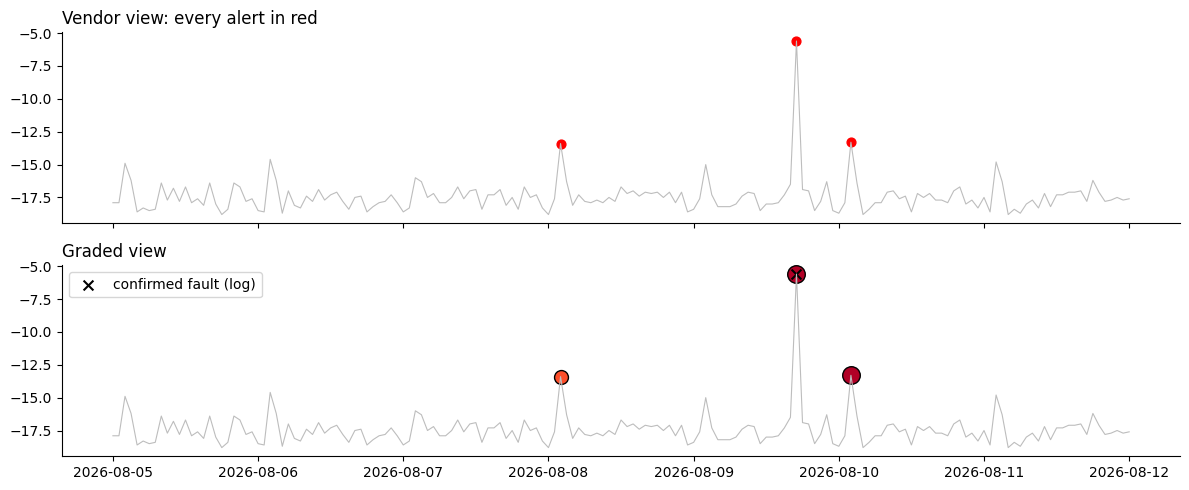

In [13]:
def emphasis(score):
    """Return (colour, marker size, edge colour) for one reading."""
    # TODO: replace the single return below with the four bands
    if score >= 0.90:
        return ("#b10026", 160, "black")
    elif score >= 0.70:
        return ("#fc4e2a", 100, "black")
    elif score >= 0.50:
        return ("white", 60, "#fc4e2a")
    else:
        return (GREY, 20, GREY)

week = df[(df.freezer_id == "FZ-B2") & (df.timestamp.between("2026-08-05", "2026-08-12"))]
if ready(emphasis(0.95)):
    fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    ax[0].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)
    a = week[week.ai_flag == 1]
    ax[0].scatter(a.timestamp, a.temp_c, color="red", s=40)
    ax[0].set_title("Vendor view: every alert in red", loc="left")
    ax[1].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)
    for _, r in week[week.ai_score >= 0.5].iterrows():
        col, size, edge = emphasis(r.ai_score)
        ax[1].scatter(r.timestamp, r.temp_c, color=col, s=size, edgecolors=edge)
    f_ = week[week.confirmed_fault == 1]
    ax[1].scatter(f_.timestamp, f_.temp_c, marker="x", color="k", s=50, label="confirmed fault (log)")
    ax[1].legend(loc="upper left")
    ax[1].set_title("Graded view", loc="left")
    plt.tight_layout()
    plt.show()


### 7b · "A score of 0.92 means 92%"? Count it.
Wilke: people read probabilities better as **frequencies**. Of all alerts in a score band, how many were real?

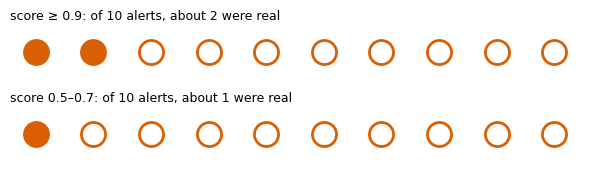

In [14]:
band_hi = df[df.ai_score >= 0.9]
band_lo = df[(df.ai_score >= 0.5) & (df.ai_score < 0.7)]

real_per_10_hi = round(band_hi["confirmed_fault"].mean() * 10)   # TODO: of 10 alerts with score >= 0.9, about how many were real faults? (round to a whole number)
real_per_10_lo = round(band_lo["confirmed_fault"].mean() * 10)   # TODO: same for scores 0.5-0.7

if ready(real_per_10_hi, real_per_10_lo):
    fig, ax = plt.subplots(2, 1, figsize=(6, 1.8))
    for a_, k, lab in zip(ax, [real_per_10_hi, real_per_10_lo], ["score ≥ 0.9", "score 0.5–0.7"]):
        for i in range(10): a_.scatter(i, 0, s=300, color=ACCENT if i < k else "white", edgecolors=ACCENT, linewidths=2)
        a_.axis("off")
        a_.set_title(f"{lab}: of 10 alerts, about {k} were real", loc="left", fontsize=9)
    plt.tight_layout()
    plt.show()


**✏️ Your answer (Part 7):** (a) Why does a red dot at every alert make Ravi's team **more** likely to miss the frozen H2 sensor? Use the words *salience* and *inattentional blindness*. (b) Rewrite vendor statement 6 using frequency framing.

(a)

*My answer:* When every alert is the same bright red dot, every alert has the same *salience*, no matter how confident the model is, so a 0.51 borderline alert and a 0.98 near-certain fault pull the same amount of attention. On top of that, most of those red dots are false alarms from the defrost cycle, so the team gets used to red dots meaning nothing. This is *inattentional blindness*: because they see the same loud signal over and over with nothing behind it, they stop looking carefully, and they are even less likely to notice that FZ-H2 is silently stuck, because that fault never raises an alert and has no red dot at all.

(b)

*My answer:* Honest version: "Out of every 10 alerts with a score of 0.90 or more, only about 2 turn out to be real faults. A high score helps narrow things down, but it is not a 92% guarantee." Saying it as a count out of 10 is easier to judge correctly than a percentage like 0.92.


---
## Part 8 · Standard deviation vs standard error (vendor statement 8)

The vendor judged a new FZ-B1 reading of **−15.9 °C at 14:00** against the 14:00 baseline.

In [15]:
base = df[(df.freezer_id == "FZ-B1") & (df.hour == 14) & (df.confirmed_fault == 0)]["temp_c"]
mu, sd, n = base.mean(), base.std(), len(base)
new_reading = -15.9

se = sd / np.sqrt(n)        # TODO: standard error of the baseline mean
z_sd = (new_reading - mu) / sd      # TODO: (new_reading - mu) / sd
z_se = (new_reading - mu) / se      # TODO: (new_reading - mu) / se

if ready(se, z_sd, z_se):
    print(f"baseline: mean {mu:.2f} °C, SD {sd:.2f}, n = {n}, SE = {se:.3f}")
    print(f"z using SD = {z_sd:.1f} | z using SE = {z_se:.1f}")

correct_z = "SD"   # TODO: 'SD' or 'SE' - which one should be used to judge a single new reading?


baseline: mean -17.31 °C, SD 0.61, n = 42, SE = 0.094
z using SD = 2.3 | z using SE = 15.0


**✏️ Your answer (Part 8):** In one sentence each, say what the SD and the SE describe, and rewrite vendor statement 8.

*My answer:* The SD describes how much *individual* 14:00 readings naturally vary around the baseline mean, so it is the right scale for judging one new reading. The SE describes how precisely we know the *mean itself*, and it gets smaller as we collect more data, so it is not meant for judging a single reading. Honest version of statement 8: "A new FZ-B1 reading of -15.9 °C at 14:00 is about 2.3 standard deviations above the usual 14:00 baseline (mean -17.3 °C). That is unusually warm and worth checking, but it is not the '15 sigma, definite fault' that the vendor's SE-based calculation claims." The vendor got 15 by dividing by the SE instead of the SD, which is the wrong comparison for a single reading.


---
## Part 9 · Triage the vendor report

For each statement decide: **Accept** (correct as stated), **Correct** (useful, but the wording or number must change) or **Reject** (not supported). Then measure the report.

In [16]:
decisions = {
    1: "Reject",   # 97.9% accurate, so trustworthy
    2: "Reject",   # most faults happen around 2 am
    3: "Accept",   # all 10 compressor trips caught
    4: "Reject",   # FZ-H2 had no fault
    5: "Reject",   # -14 °C is abnormal at any time
    6: "Reject",   # score 0.92 = 92% chance
    7: "Correct",   # threshold 0.5 is best
    8: "Reject",   # 15 standard errors: definite fault
}

if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    print(f"Statements accepted as written: {accepted}/{len(decisions)} ({accepted / len(decisions):.0%})")
    print(pd.Series(decisions).value_counts().to_string())
else:
    print("⚠ Fill in all eight decisions with 'Accept', 'Correct' or 'Reject'.")


Statements accepted as written: 1/8 (12%)
Reject     6
Accept     1
Correct    1


**✏️ Your answer (Part 9):** Sketch (in words or a quick drawing) the **anomaly review view** you would give Ravi's team instead of the vendor's red-dot dashboard. Name at least four parts: main view, context, queue, verification tools, evaluation.

*My answer:*
- **Main view:** one time-series line per freezer, with graded emphasis (strong, moderate, subtle, none, like in Part 7a) instead of the same red dot for every alert, so you can see how confident each alert is at a glance.
- **Context:** behind the line, show that freezer's own baseline for that hour of day (median with a MAD band) and shade the scheduled defrost window, so a normal 02:00 warm-up is visually different from a genuinely strange reading.
- **Queue:** a ranked list of open alerts, sorted by score band, with a short reason tag on each (for example "above hour baseline" or "flat for 6 hours"), instead of one undifferentiated pile of red dots.
- **Verification tools:** one click on an alert shows the raw readings around it and that freezer's past confirmed faults, plus a button to mark the alert as real or false, so every check feeds back into the system.
- **Evaluation:** a small rolling panel showing precision and recall (not accuracy) against the maintenance log, so the team can see over time whether the alerts are actually useful, not just whether one big accuracy number looks nice.


---
## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which vendor statement did you find most convincing? Was it the number, the confident tone, or the red dots? Would you have caught the problem without the maintenance log?

*My reflection:* Statement 1 ("97.9% accurate") was the most convincing one for me at first. A single number so close to 100% just feels like proof, and the confident tone adds to it. Honestly, without the maintenance log I probably would have accepted it. The trick, that a "never alert" system scores even higher at 99.4%, is not something I would have thought to check on my own.

**2. Who sets the threshold?** The threshold decides how many night call-outs happen and how many freezers spoil. Who at FreshKart should own that choice, and what information should the dashboard show them?

*My reflection:* It should not be left as a hidden default set by the vendor. It is a business trade-off, so it should be owned jointly by the cold-chain lead (Ravi), who pays the cost of wasted call-outs, and whoever owns inventory loss, who pays when a freezer spoils. The dashboard should show them the cost curve across thresholds and the precision/recall at each setting, like in Part 5, so the choice is made with the real trade-off visible.

**3. Missing ground truth.** You had a maintenance log. In real life, faults nobody inspected never get a label. How would that change your precision and recall numbers, and how could the review workflow reduce the problem?

*My reflection:* Without the maintenance log, any fault that nobody inspected would silently count as "normal", so real faults would be hidden in the normal bucket and recall would look better than it really is. Precision would be less affected because it only looks at readings that did alert, though some "false alarms" might actually have been real faults nobody checked. A review workflow that sends every alert plus a small random sample of non-alerts to a technician would at least estimate how many real faults are hiding among the "normal" readings.

**4. Designing against over-trust.** Name one design change (encoding, interaction, wording) that would make technicians *check* an alert rather than simply obey or ignore it.

*My reflection:* I would replace the single red dot with the graded emphasis from Part 7a and add a one-line reason tag to every alert, like "score 0.93, outside defrost window" or "score 0.55, during defrost". When an alert comes with a short reason and a visible confidence level, checking it becomes part of reading it, instead of the technician either blindly obeying a red dot or tuning it out completely.
